In [110]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

In [111]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [112]:
PATH_data = f"../../../../mnt/d/swampy_data/genotype/reduced/22"

In [113]:
mafs = []
for f in os.listdir(PATH_data):
    mafs.append(float(f.split("_maf_")[1].split("_")[0]))
mafs = list(set(mafs))
mafs.sort()

In [114]:
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [115]:
for maf in mafs:
    file_name = [f for f in os.listdir(PATH_data) if f.split("_maf_")[1].split("_")[0] == str(maf)][0]
    PATH_mini_dim = f"../../../../mnt/d/swampy_data/genotype/reduced/22/{file_name}"
    dim = pd.read_pickle(PATH_mini_dim)
    humans[f"dim1_maf_{maf}"] = dim['dim1']
    humans[f"dim2_maf_{maf}"] = dim['dim2']

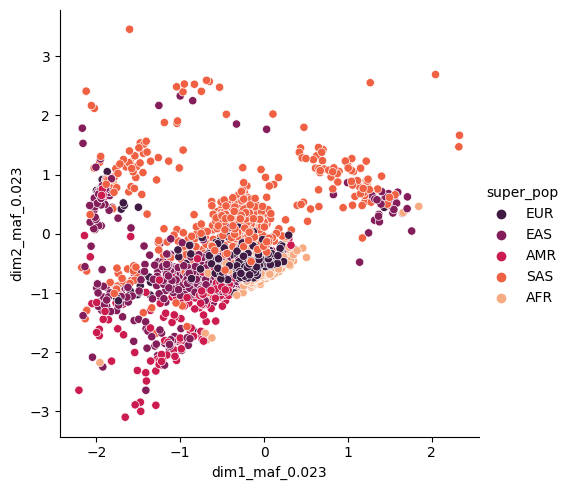

In [116]:
nr = 2
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{mafs[nr]}", y=f"dim2_maf_{mafs[nr]}",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

In [117]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
for maf in mafs:
    file_name = [f for f in os.listdir(PATH_data) if f.split("_maf_")[1].split("_")[0] == str(maf)][0]
    PATH_mini_dim = f"../../../../mnt/d/swampy_data/genotype/reduced/22/{file_name}"
    dim = pd.read_pickle(PATH_mini_dim)
    humans[f"pheno_maf_{maf}"] = dim['dim1'] + dim['dim2']

In [119]:
humans.to_pickle('./data/phenotype/humans_maf_popstrat.pkl')